# Bressoux scenario setup

Prepares everything `main.py` needs for `data/bressoux/`, split in two:

- `inputs/` -- TRUE inputs, never overwritten by this notebook: the raw
  smart-meter data (`part-*.csv`), `coordinates.csv`, the topology builder
  (`network.py`), and the PV installation register (`pv_installations.csv`).
- `out/processed/` -- DERIVED data this notebook generates: `metadata.csv`,
  `load_profiles.csv`, `mv_load_profiles.csv`, and the cached PVGIS
  irradiance reference.

Steps:

1. builds the Bressoux LV/MV network (`inputs/network.py`) and sanity-checks it,
2. visualizes it on a real map (Folium),
3. generates household consumption profiles from the 33 real EAN smart meters
   plus per-household metadata (`out/processed/load_profiles.csv`, `metadata.csv`),
4. generates the 4 MV load facility profiles (`out/processed/mv_load_profiles.csv`),
5. materializes the PVGIS irradiance reference needed for PV production
   (`out/processed/pvgis_irradiance_quarter_hourly.parquet`).

Run this notebook with the **repository root** as the working directory
(same convention as `profil_conso.ipynb` / `analyze_Bressoux_data.ipynb`).

In [1]:
import json
import os
import random

import numpy as np
import pandas as pd
import folium
import matplotlib.pyplot as plt

from digital_twin.utils import load_site_network, STEPS_PER_DAY
from digital_twin.data_processing.profiles import build_irradiance_reference, generate_household_profiles

DATA_PATH = "data/bressoux/"
INPUTS_DIR = os.path.join(DATA_PATH, "inputs")
OUT_DIR = os.path.join(DATA_PATH, "out/processed")
SEED = 42

assert os.path.exists(os.path.join(INPUTS_DIR, "network.py")), (
    "inputs/network.py not found -- run this notebook with the repository root "
    "as the working directory."
)

## 1. Build the network

In [2]:
config = {"data_path": DATA_PATH, "trafo_sn_mva": 0.22}
network = load_site_network(config)
net = network["net"]

print(f"Buses: {len(net.bus)} (expected 346)")
print(f"Lines: {len(net.line)} (expected 341)")
print(f"Transformers: {len(net.trafo)} (expected 4)")
print(f"Residential buses: {len(network['buses'])} (expected 333)")
print(f"MV nodes: {len(network['mv_nodes'])} (expected 9)")
if network["warnings"]:
    print("Warnings:")
    for w in network["warnings"]:
        print(" -", w)
else:
    print("No topology warnings.")

Buses: 346 (expected 346)
Lines: 341 (expected 341)
Transformers: 4 (expected 4)
Residential buses: 333 (expected 333)
MV nodes: 9 (expected 9)
No topology warnings.


## 2. Visualize the network on a real map

In [3]:
def _bus_latlon(bus_id):
    geo = json.loads(net.bus.loc[bus_id, "geo"])
    lon, lat = geo["coordinates"]
    return lat, lon

m = folium.Map(location=_bus_latlon(network["mv_nodes"]["SLACK"]), zoom_start=16, tiles="OpenStreetMap")

# Residential LV buses
for (street, num), bus_id in network["buses"].items():
    lat, lon = _bus_latlon(bus_id)
    folium.CircleMarker(
        location=(lat, lon), radius=3, color="#4C78A8", fill=True, fill_opacity=0.7,
        popup=f"{street} {num} (bus {bus_id})",
    ).add_to(m)

# MV substations (with transformer)
for name in ["TROULOUETTE", "CIMETIERE BRESSOUX", "MALVOZ BRESSOUX", "GROTTES"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="red", icon="bolt", prefix="fa"),
        popup=f"Substation: {name} (bus {bus_id})",
    ).add_to(m)

# MV load nodes (large consumers, no transformer)
for name in network["mv_load_names"]:
    bus_id = network["mv_nodes"][name]
    lat, lon = _bus_latlon(bus_id)
    folium.Marker(
        location=(lat, lon), icon=folium.Icon(color="green", icon="building", prefix="fa"),
        popup=f"MV load: {name} (bus {bus_id})",
    ).add_to(m)

# Slack (external grid connection)
lat, lon = _bus_latlon(network["mv_nodes"]["SLACK"])
folium.Marker(
    location=(lat, lon), icon=folium.Icon(color="black", icon="plug", prefix="fa"),
    popup="SLACK (external grid)",
).add_to(m)

m

## 3. Generate household metadata + consumption profiles

In [4]:
n_profiles = len(network["buses"])  # size the bank to the real network (333)
households, metadata = generate_household_profiles(n_profiles, seed=SEED)

os.makedirs(OUT_DIR, exist_ok=True)
households.to_csv(os.path.join(OUT_DIR, "load_profiles.csv"))
metadata.to_csv(os.path.join(OUT_DIR, "metadata.csv"), index=False)

print(f"households: {households.shape[0]} steps x {households.shape[1]} profiles -> "
      f"{os.path.join(OUT_DIR, 'load_profiles.csv')}")
print(f"metadata: {len(metadata)} rows -> {os.path.join(OUT_DIR, 'metadata.csv')}")
metadata.head()

households: 672 steps x 333 profiles -> data/bressoux/out/processed/load_profiles.csv
metadata: 333 rows -> data/bressoux/out/processed/metadata.csv


,profile_id,constellation,building_type,heat_pump,electric_water_heating,electric_vehicle_type,n_persons,pv_system_size_kwp,battery_size_kwh,source_street,source_ean_index
0,0,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,2
1,1,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,25
2,2,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,21
3,3,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,14
4,4,<NA>,<NA>,False,False,<NA>,<NA>,0.0,0.0,Avenue Joseph Merlot,14


All scenario columns (`heat_pump`, `electric_water_heating`, `pv_system_size_kwp`,
`battery_size_kwh`, `n_persons`, `constellation`, `building_type`,
`electric_vehicle_type`) default to `False`/`0.0`/unknown — no household is
equipped with anything yet. These get edited later to define different
scenarios (e.g. flip flags on a subset of households) without needing to
regenerate the profiles themselves.

This update is to be done later. Do a small analysis as well of the households composition afterwards. Add profiles of different assets here using resflex package.

In [5]:
metadata[["heat_pump", "electric_water_heating"]].value_counts()

heat_pump  electric_water_heating
False      False                     333
Name: count, dtype: int64

## 4. Generate the MV load facility profiles

The 4 MV load facilities (rest home, school, sports hall, horticultural
centre) are large consumers connected directly at MV, each with its own
deterministic day/time profile (not drawn from the residential EAN data).
Ported from the historical `profil_conso.ipynb`: pure electricity consumption
only (lighting, IT, ventilation, pumps, lifts, kitchen) -- space/water heating
is excluded (a different energy vector).

In [6]:
random.seed(SEED)

N_PER_WEEK = 7 * 96
_days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
time_index = [
    f"{_days[step // 96]} {(step % 96) * 15 // 60:02d}:{(step % 96) * 15 % 60:02d}"
    for step in range(N_PER_WEEK)
]


def get_mr_power(day_of_week, time_val):
    """Rest home ('Paradis du Bouhay') -- lighting, kitchen, lifts, cold rooms
    and auxiliaries. Space/water heating excluded (separate energy vector)."""
    power = 28.0
    is_weekend = day_of_week >= 5
    if 6.5 <= time_val < 11.5:
        power = 42.0
    elif 11.5 <= time_val < 14.0:
        power = 58.0
    elif 14.0 <= time_val < 17.5:
        power = 38.0
    elif 17.5 <= time_val < 20.0:
        power = 48.0
    elif 20.0 <= time_val < 22.5:
        power = 34.0
    if is_weekend:
        power *= 0.92
    return power * random.uniform(0.96, 1.04)


def get_ecole_power(day_of_week, time_val):
    """School ('Groupe Scolaire') -- lighting, IT, ambient ventilation. Heating
    excluded."""
    is_weekend = day_of_week >= 5
    is_wednesday = day_of_week == 2
    if is_weekend:
        return 0.8 * random.uniform(0.95, 1.05)
    if 7.5 <= time_val < 8.5:
        return 8.0 * random.uniform(0.95, 1.05)
    elif 8.5 <= time_val < 12.0:
        return 12.0 * random.uniform(0.95, 1.05)
    elif 12.0 <= time_val < 13.5:
        return 9.0 * random.uniform(0.95, 1.05)
    elif 13.5 <= time_val < 16.0:
        return (1.5 if is_wednesday else 11.0) * random.uniform(0.95, 1.05)
    elif 16.0 <= time_val < 18.0:
        return 4.0 * random.uniform(0.95, 1.05)
    else:
        return 1.2 * random.uniform(0.95, 1.05)


def get_hall_sport_power(day_of_week, time_val):
    """Sports hall ('Omnisport BX') -- track lighting and ventilation. Shower
    water heating excluded."""
    is_weekend = day_of_week >= 5
    if not is_weekend:
        if 8.0 <= time_val < 16.0:
            return 5.0 * random.uniform(0.92, 1.08)
        elif 16.0 <= time_val < 17.5:
            return 8.0 * random.uniform(0.95, 1.05)
        elif 17.5 <= time_val < 22.5:
            return 22.0 * random.uniform(0.95, 1.05)
        else:
            return 1.5 * random.uniform(0.95, 1.05)
    else:
        if 8.5 <= time_val < 21.5:
            return 18.0 * random.uniform(0.93, 1.07)
        else:
            return 1.8 * random.uniform(0.95, 1.05)


def get_horticole_power(day_of_week, time_val):
    """Horticultural centre ('Plantations') -- grow lighting, irrigation pumps,
    greenhouse vents. Greenhouse heating excluded."""
    is_weekend = day_of_week >= 5
    base_tech = 2.5 if is_weekend else 3.5
    if 7.5 <= time_val < 16.5:
        activity = 8.0 if not is_weekend else 1.5
        return (base_tech + activity) * random.uniform(0.95, 1.05)
    else:
        return base_tech * random.uniform(0.95, 1.05)


mv_load_profiles_kw = {name: [] for name in network["mv_load_names"]}
for step in range(N_PER_WEEK):
    dow = step // 96
    time_val = (step % 96) * 15 / 60.0
    mv_load_profiles_kw["Paradis du Bouhay"].append(get_mr_power(dow, time_val))
    mv_load_profiles_kw["Groupe Scolaire"].append(get_ecole_power(dow, time_val))
    mv_load_profiles_kw["Omnisport BX"].append(get_hall_sport_power(dow, time_val))
    mv_load_profiles_kw["Plantations"].append(get_horticole_power(dow, time_val))

mv_load_profiles = pd.DataFrame(mv_load_profiles_kw, index=time_index) / 1000.0  # kW -> MW
mv_load_profiles.index.name = "week_step"
mv_load_profiles.to_csv(os.path.join(OUT_DIR, "mv_load_profiles.csv"))
print(f"mv_load_profiles: {mv_load_profiles.shape} -> "
      f"{os.path.join(OUT_DIR, 'mv_load_profiles.csv')}")
mv_load_profiles.describe()

mv_load_profiles: (672, 4) -> data/bressoux/out/processed/mv_load_profiles.csv


,Paradis du Bouhay,Plantations,Omnisport BX,Groupe Scolaire
count,672.000000,672.000000,672.000000,672.000000
mean,0.037324,0.005527,0.008282,0.003518
std,0.009468,0.003652,0.008015,0.004150
min,0.024823,0.002377,0.001425,0.000760
25%,0.028345,0.003393,0.001556,0.000830
50%,0.036944,0.003575,0.004937,0.001204
75%,0.042705,0.011013,0.017562,0.004056
max,0.060176,0.012071,0.023059,0.012589


Should be validated.

## 5. Generate the PV irradiance reference

Needed by `process_data` to build `pv_profiles` from
`inputs/pv_installations.csv` (see `digital_twin.data_processing.pv.build_pv_production`).
Fetched once from PVGIS and cached -- skipped if already materialized.

In [7]:
irradiance_path = os.path.join(OUT_DIR, "pvgis_irradiance_quarter_hourly.parquet")

if os.path.exists(irradiance_path):
    print(f"Already materialized: {irradiance_path}")
else:
    build_irradiance_reference(out_path=irradiance_path)

Already materialized: data/bressoux/out/processed/pvgis_irradiance_quarter_hourly.parquet


## 6. Sanity check plots

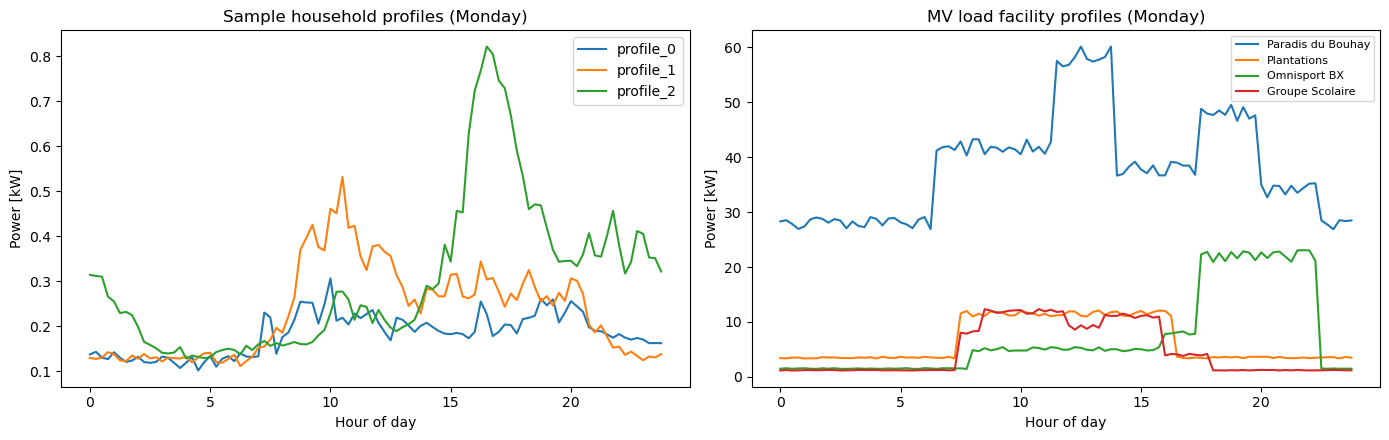

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

t = np.arange(STEPS_PER_DAY) * 0.25
for i in range(3):
    day_vals = households[f"profile_{i}"].to_numpy()[:STEPS_PER_DAY] * 1000  # MW -> kW
    axes[0].plot(t, day_vals, label=f"profile_{i}")
axes[0].set_title("Sample household profiles (Monday)")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Power [kW]")
axes[0].legend()

for name in network["mv_load_names"]:
    day_vals = mv_load_profiles[name].to_numpy()[:STEPS_PER_DAY] * 1000  # MW -> kW
    axes[1].plot(t, day_vals, label=name)
axes[1].set_title("MV load facility profiles (Monday)")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Power [kW]")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sample_profiles.png"), dpi=300)
plt.show()

## Next step

With `inputs/network.py`, `inputs/pv_installations.csv` and the generated
`out/processed/{metadata,load_profiles,mv_load_profiles,pvgis_irradiance_quarter_hourly}`
files in place, run the digital twin:

```bash
python main.py
```

For an already-done example, you can also specify the simulation parameters
by modifying the `config` dictionary in `main.py`. Set `config['save'] = True`
to write a Markdown report (summary/violations/warnings) to
`data/bressoux/out/results/`.
